# Review Insight AI · 실제 실행 결과
학습은 scripts/train.py에서 실행했다. 이 노트북은 저장한 학습 로그·평가·가중치를 실제로 읽어 검증한다. 이미 완료한 학습은 재사용하며 존재하지 않는 결과를 만들지 않는다. 재학습은 다음 셀의 주석을 해제한다.

In [1]:
from pathlib import Path
import os, sys, json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
# import subprocess; subprocess.run([sys.executable, str(ROOT/'scripts/train.py')], check=True)
print('Saved training experiment:',json.loads((ROOT/'reports/training_environment.json').read_text())['models'])

Saved training experiment: [{'model': 'word_lr', 'validation_f1': 0.8026409200624733, 'C': 2.0, 'training_seconds': 18.580606100033037, 'train_rows': 116769, 'max_features': 100000, 'analyzer': 'word', 'ngrams': '(1, 2)', 'accuracy': 0.8162636158114681, 'precision': 0.8379970544918999, 'recall': 0.7824532453245324, 'f1': 0.8092732186033281}, {'model': 'char_lr', 'validation_f1': 0.8680311487836814, 'C': 2.0, 'training_seconds': 85.85194149997551, 'train_rows': 116769, 'max_features': 100000, 'analyzer': 'char', 'ngrams': '(2, 5)', 'accuracy': 0.8699047749537576, 'precision': 0.8728660652324775, 'recall': 0.8648239823982399, 'f1': 0.8688264143123575}]


In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(ROOT/'reports/comparison.csv'))
print((ROOT/'reports/data_audit.json').read_text(encoding='utf-8'))

,model,validation_f1,C,training_seconds,train_rows,max_features,analyzer,ngrams,accuracy,precision,recall,f1
0,word_lr,0.802641,2.0,18.580606,116769,100000,word,"(1, 2)",0.816264,0.837997,0.782453,0.809273
1,char_lr,0.868031,2.0,85.851941,116769,100000,char,"(2, 5)",0.869905,0.872866,0.864824,0.868826


{
  "source": "과제4_제출\\assignment4_results\\20261112_215141_581845\\ratings_train.txt",
  "source_sha256": "e03b7d14e9e41be8d464a28057cd25d7396c53e67aa7fd5f7e552c59b0ee2940",
  "raw_nonmissing": 149995,
  "clean_unique": 145962,
  "conflicting_texts_removed": 160,
  "split_ratio": [
    0.8,
    0.1,
    0.1
  ],
  "seed": 42,
  "split_counts": {
    "train": {
      "size": 116769,
      "class_counts": {
        "0": 58599,
        "1": 58170
      }
    },
    "validation": {
      "size": 14596,
      "class_counts": {
        "0": 7325,
        "1": 7271
      }
    },
    "test": {
      "size": 14597,
      "class_counts": {
        "0": 7325,
        "1": 7272
      }
    }
  },
  "note": "Only original NSMC training file used. Official test not used; local fixed holdout is test. Prior coursework used NSMC: provenance disclosed."
}


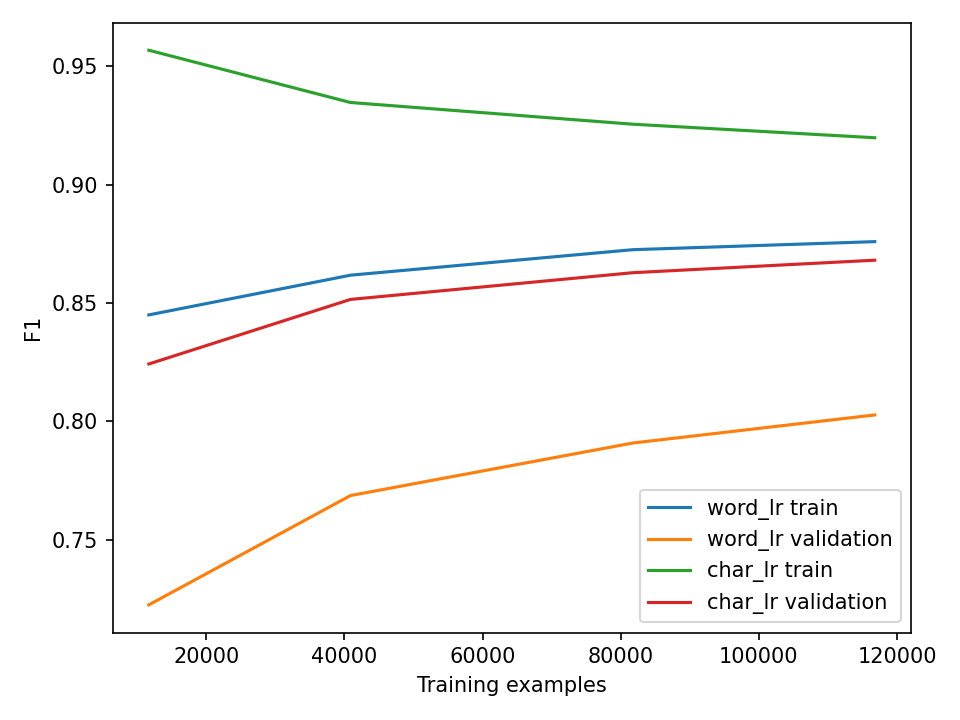

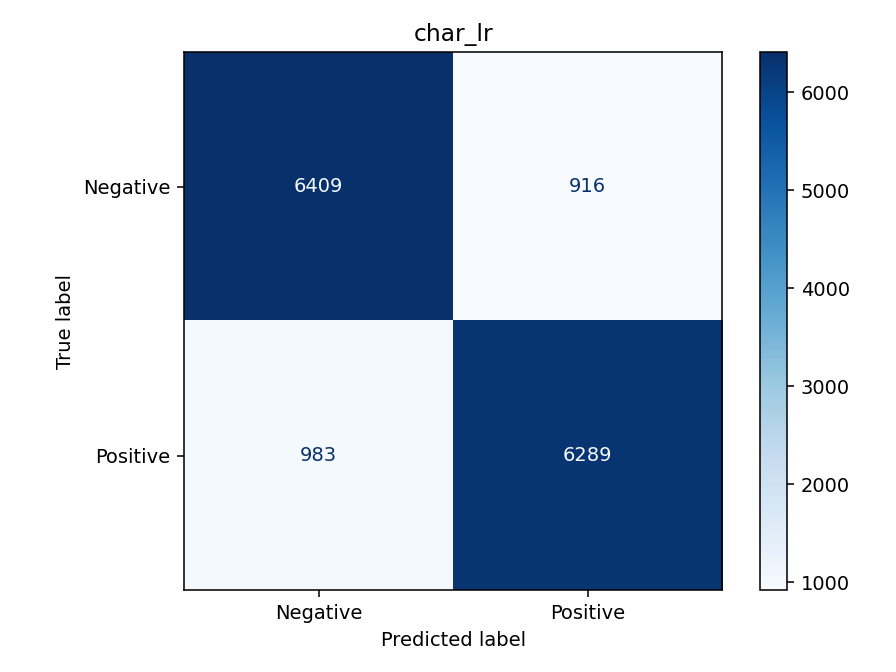

In [3]:
display(Image(filename=str(ROOT/'reports/learning_curves.png')))
display(Image(filename=str(ROOT/'reports/char_lr_confusion.png')))

In [4]:
from src.core import analyze
print(json.dumps(analyze(['배우들 연기도 어색하고 스토리도 너무 뻔했음.','영화는 재미있지만 음악이 별로였다.']),ensure_ascii=False,indent=2))
print((ROOT/'reports/aspect_training.json').read_text(encoding='utf-8'))

[
  {
    "review": "배우들 연기도 어색하고 스토리도 너무 뻔했음.",
    "domain": "movie",
    "sentiment": "부정",
    "positive_probability": 0.044872139204748675,
    "confidence": 0.9551278607952514,
    "uncertain": false,
    "complaints": [
      "연기 및 캐스팅",
      "스토리 및 전개"
    ],
    "aspect_status": "weak_supervision_experimental",
    "aspect_probabilities": {
      "연기 및 캐스팅": 0.9996799626366987,
      "스토리 및 전개": 0.9988747339090673,
      "연출 및 편집": 0.41511767915802444,
      "영상 및 시각효과": 0.35222054983407325,
      "음악 및 음향": 0.04043344965500318,
      "기타": 0.03522921494625592
    }
  },
  {
    "review": "영화는 재미있지만 음악이 별로였다.",
    "domain": "movie",
    "sentiment": "부정",
    "positive_probability": 0.12808171478794453,
    "confidence": 0.8719182852120555,
    "uncertain": false,
    "complaints": [
      "음악 및 음향"
    ],
    "aspect_status": "weak_supervision_experimental",
    "aspect_probabilities": {
      "연기 및 캐스팅": 0.02836076057964934,
      "스토리 및 전개": 0.0326058511614914,
      "연출 

In [5]:
display(pd.read_csv(ROOT/'reports/char_lr_errors.csv').head(10))
print((ROOT/'reports/runtime_checks.json').read_text(encoding='utf-8'))

,id,text,label,prediction
0,5424,뷁!!,0,1
1,7084513,"희대의영화 천재감독 쿠엔틴 타란티노가,킬빌의여주인공 블랙맘바(우마 서먼 분)의 라이...",1,0
2,5993134,식상한면이 있었다 근데 왜 네이버에서 나의 영화평점을 자꾸 삭제하세요??,0,1
3,9712693,앞뒤를 알고 영화에 배경을 알게되면 과연 평점이 이리 나올수 있을까 의문이 드네요,0,1
4,6715639,저기요 ;;밑에분 보지도않고 잘알지도않고 ᄏᄏ뭐하는거?OOO ᄏᄏᄏᄏᄏ기대하겠습니당,1,0
5,3681737,다른 유괴 영화와 색다르간 허지만 어따가 테이큰이랑 비교해?,0,1
6,9139036,불만제로 확실한 결과물인지 궁금하네요 실제로 어떤물건이든 만족하는 사람과 불만족인 ...,0,1
7,8627616,"이런 평점 테러, 네이버에서 좀 막아야 하는 것 아닌가?",1,0
8,10116985,어쩜 이렇게 연기를 못할 수 있는지...이걸 상영하는 극장들의 신기하네요.,0,1
9,8819684,기분좋게 틀었는데 지금 굉장히 잡쳤다,0,1


{
  "train_validation_overlap": 0,
  "train_test_overlap": 0,
  "validation_test_overlap": 0,
  "preprocessing": true,
  "model_inference": [
    {
      "review": "배우들 연기도 어색하고 스토리도 너무 뻔했음.",
      "domain": "movie",
      "sentiment": "부정",
      "positive_probability": 0.044872139204748675,
      "confidence": 0.9551278607952514,
      "uncertain": false,
      "complaints": [
        "연기 및 캐스팅",
        "스토리 및 전개"
      ],
      "aspect_status": "weak_supervision_experimental",
      "aspect_probabilities": {
        "연기 및 캐스팅": 0.9996799626366987,
        "스토리 및 전개": 0.9988747339090673,
        "연출 및 편집": 0.41511767915802444,
        "영상 및 시각효과": 0.35222054983407325,
        "음악 및 음향": 0.04043344965500318,
        "기타": 0.03522921494625592
      }
    },
    {
      "review": "영화가 정말 재미있고 훌륭했다.",
      "domain": "movie",
      "sentiment": "긍정",
      "positive_probability": 0.977314445445063,
      "confidence": 0.977314445445063,
      "uncertain": false,
      "complaints": [],